# 04 数据增强消融（E3）

固定 E1 骨干与 E2 微调策略，比较 None、Basic、Combined。None 仍含确定性缩放、张量转换与 ImageNet 归一化。

**前置条件：** 完成 E2 并保存选择；增强参数定义在 src/data.py，本阶段只改变随机增强。

全部模型选择只依据 **PlantVillage 验证集 Macro-F1**，本 Notebook 不读取 PlantVillage 测试图片或 PlantDoc。训练参数来自配置，默认 224×224、batch size 16、最多 10 轮、AdamW、交叉熵与 Early Stopping；改变配置前先记录理由。

`RUN_TRAINING=False` 时只读取配置和已有记录，不下载权重或训练。打开训练后，已完成且配置和数据指纹一致的候选自动跳过；未完成候选采用新的 run_id 重新训练，旧中断记录仍可识别。


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        for root in (candidate, candidate / "plant-disease-project"):
            if (root / "configs" / "base.yaml").is_file():
                return root
    raise FileNotFoundError("请在项目根目录或 notebooks 目录打开本 Notebook。")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_config, load_labels

BASE = load_config(PROJECT_ROOT / "configs" / "base.yaml")
EXPERIMENTS = load_config(PROJECT_ROOT / "configs" / "experiments.yaml")
LABELS = load_config(PROJECT_ROOT / "configs" / "labels.yaml")
CLASS_NAMES = [item["label"] for item in load_labels(PROJECT_ROOT)]
assert len(CLASS_NAMES) == 8 and len(set(CLASS_NAMES)) == 8
assert [item["label_index"] for item in LABELS["classes"]] == list(range(8))
print("项目目录：", PROJECT_ROOT)
print("类别数量：", len(CLASS_NAMES), "；随机种子：", BASE["seed"])


项目目录： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project
类别数量： 8 ；随机种子： 42


## 1. 查看计划与运行状态

先确认候选和基础配置。MPS 可用时优先使用，必要时回退 CPU。每个正式实验有独立目录，保存实际配置、标签、数据指纹、环境、状态、最佳权重和历史；不得把烟测结果用作模型选择。


In [8]:
from src.experiments import run_stage, stage_results, run_statuses, select_best, selected_run

STAGE = "E3"
RUN_TRAINING = True
SAVE_SELECTION = True

print("阶段：", STAGE)
print("候选：", EXPERIMENTS.get("augmentations"))
print("基础训练参数：")
display(BASE["training"])
print("策略学习率：", BASE["training"].get("lr_by_strategy"))
print("已选择骨干：", EXPERIMENTS.get("selected_backbone"))
print("已选择微调：", EXPERIMENTS.get("selected_finetuning"))
print("已选择增强：", EXPERIMENTS.get("selected_augmentation"))
display(pd.DataFrame(run_statuses(PROJECT_ROOT)))


阶段： E3
候选： ['none', 'basic', 'combined']
基础训练参数：


{'epochs': 10,
 'batch_size': 16,
 'optimizer': 'AdamW',
 'lr': 0.001,
 'lr_by_strategy': {'freeze': 0.001, 'partial': 0.0001, 'full': 0.0001},
 'weight_decay': 0.0001,
 'early_stopping': True,
 'patience': 3,
 'num_workers': 0,
 'monitor': 'val_macro_f1'}

策略学习率： {'freeze': 0.001, 'partial': 0.0001, 'full': 0.0001}
已选择骨干： efficientnet_b0
已选择微调： full
已选择增强： None


,run_id,stage,model,finetuning,augmentation,status,smoke_test,epochs_completed,seconds,error
0,e1_efficientnet_b0_freeze_basic_s42_20261021T0...,E1,efficientnet_b0,freeze,basic,completed,False,10,564.835715,None
1,e1_mobilenet_v2_freeze_basic_s42_20261021T0506...,E1,mobilenet_v2,freeze,basic,completed,False,10,463.776880,None
2,e1_resnet18_freeze_basic_s42_20261021T045915_a...,E1,resnet18,freeze,basic,completed,False,10,427.105395,None
3,e2_efficientnet_b0_freeze_basic_s42_20261021T0...,E2,efficientnet_b0,freeze,basic,completed,False,10,598.054591,None
4,e2_efficientnet_b0_full_basic_s42_20261021T054...,E2,efficientnet_b0,full,basic,completed,False,7,1276.950187,None
5,e2_efficientnet_b0_partial_basic_s42_20261021T...,E2,efficientnet_b0,partial,basic,completed,False,8,501.635882,None
6,e3_efficientnet_b0_full_basic_s42_20261021T063...,E3,efficientnet_b0,full,basic,completed,False,7,1273.615404,None
7,e3_efficientnet_b0_full_combined_s42_20261021T...,E3,efficientnet_b0,full,combined,completed,False,10,1948.731437,None
8,e3_efficientnet_b0_full_none_s42_20261021T0608...,E3,efficientnet_b0,full,none,completed,False,8,1502.628133,None
9,run_20261021T042510_f673d06c,E1,resnet18,freeze,basic,completed,True,1,1.024261,None


## 2. 运行本阶段训练

确认配置后，在上一格把 `RUN_TRAINING` 改为 `True`，重新运行上一格，再运行本格。训练过程可能持续较久；完成后查看下一节真实结果。训练异常会保留失败状态；内核被强制关闭时，状态和不完整文件仍可识别，重新运行会建立新实验。


In [5]:
prerequisite_ready = True
try:
    prerequisite_run = selected_run(PROJECT_ROOT, "E2")
    print("上阶段选定实验：", prerequisite_run.name)
except (ValueError, FileNotFoundError) as error:
    prerequisite_ready = False
    print("请先完成上一阶段并保存选择：", error)

if not RUN_TRAINING:
    print("训练关闭：目前只展示计划与已有结果。")
elif not prerequisite_ready:
    print("前置选择尚未完成，暂不训练。")
else:
    for run_dir in run_stage(PROJECT_ROOT, STAGE):
        print("已完成：", run_dir.name)


上阶段选定实验： e2_efficientnet_b0_full_basic_s42_20261021T054511_b4f88c
e3_efficientnet_b0_full_none_s42_20261021T060853_6a952d | epoch 1: train_loss=0.3486, val_macro_f1=0.9806
e3_efficientnet_b0_full_none_s42_20261021T060853_6a952d | epoch 2: train_loss=0.0610, val_macro_f1=0.9849
e3_efficientnet_b0_full_none_s42_20261021T060853_6a952d | epoch 3: train_loss=0.0342, val_macro_f1=0.9748
e3_efficientnet_b0_full_none_s42_20261021T060853_6a952d | epoch 4: train_loss=0.0264, val_macro_f1=0.9757
e3_efficientnet_b0_full_none_s42_20261021T060853_6a952d | epoch 5: train_loss=0.0202, val_macro_f1=0.9917
e3_efficientnet_b0_full_none_s42_20261021T060853_6a952d | epoch 6: train_loss=0.0117, val_macro_f1=0.9700
e3_efficientnet_b0_full_none_s42_20261021T060853_6a952d | epoch 7: train_loss=0.0146, val_macro_f1=0.9867
e3_efficientnet_b0_full_none_s42_20261021T060853_6a952d | epoch 8: train_loss=0.0086, val_macro_f1=0.9748
e3_efficientnet_b0_full_basic_s42_20261021T063356_47e126 | epoch 1: train_loss=0.3801,

## 3. 汇总完成的实验与训练曲线

仅汇总当前八类、当前清单和当前阶段参数一致的已完成正式实验。`val_macro_f1` 是最佳验证轮次对应指标，训练耗时按实际记录读取。尚无结果时不生成占位指标；中断训练不参与比较。


,run_id,stage,model,finetuning,augmentation,seed,lr,val_macro_f1,val_accuracy,val_loss,best_epoch,epochs_completed,seconds,dataset_fingerprint
0,e3_efficientnet_b0_full_combined_s42_20261021T...,E3,efficientnet_b0,full,combined,42,0.0001,0.994868,0.996025,0.019504,10,10,1948.731437,65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6...
1,e3_efficientnet_b0_full_basic_s42_20261021T063...,E3,efficientnet_b0,full,basic,42,0.0001,0.993843,0.995583,0.016419,4,7,1273.615404,65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6...
2,e3_efficientnet_b0_full_none_s42_20261021T0608...,E3,efficientnet_b0,full,none,42,0.0001,0.991728,0.991166,0.028898,5,8,1502.628133,65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6...


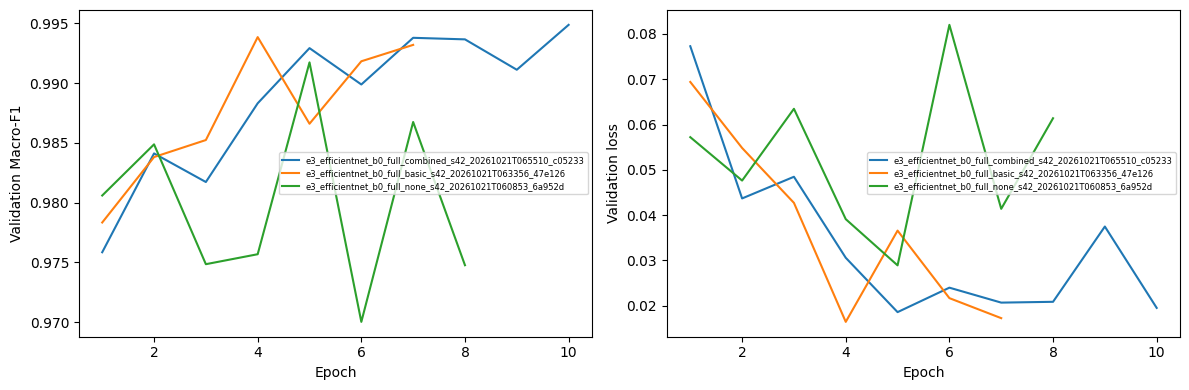

In [6]:
try:
    records = stage_results(PROJECT_ROOT, STAGE)
except (ValueError, FileNotFoundError) as error:
    records = []
    print("尚未满足数据准备或前置阶段条件：", error)
if not records:
    print("尚无本阶段完成的八分类正式结果。")
else:
    table = pd.DataFrame(records).sort_values("val_macro_f1", ascending=False)
    display(table)
    table_dir = PROJECT_ROOT / "outputs" / "tables"
    table_dir.mkdir(parents=True, exist_ok=True)
    table.to_csv(table_dir / f"{STAGE.lower()}_validation.csv", index=False, encoding="utf-8-sig")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for record in records:
        history = pd.read_csv(PROJECT_ROOT / "outputs" / "runs" / record["run_id"] / "history.csv")
        axes[0].plot(history["epoch"], history["val_macro_f1"], label=record["run_id"])
        axes[1].plot(history["epoch"], history["val_loss"], label=record["run_id"])
    axes[0].set(xlabel="Epoch", ylabel="Validation Macro-F1")
    axes[1].set(xlabel="Epoch", ylabel="Validation loss")
    for axis in axes:
        axis.legend(fontsize=6)
    plt.tight_layout()
    figure_dir = PROJECT_ROOT / "outputs" / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / f"{STAGE.lower()}_validation.png", dpi=160, bbox_inches="tight")
    plt.show()


## 4. 保存数据增强选择

查看结果后，将第 1 节 `SAVE_SELECTION` 改为 `True`，重新运行该格，再运行本格。函数要求当前阶段的全部候选都已完成，再按验证集 Macro-F1 选择并写回 `configs/experiments.yaml` 的 `selected_*` 和 `selected_runs`。并列时使用固定规则，详细比较仍保留在表格与记录中。

选择后切换到下一本 Notebook；E3 选定实验就是 Notebook 05 最终评价和 06—07 展示的模型。不要根据测试集结果回头改选。


In [9]:
if not SAVE_SELECTION:
    print("尚未保存新选择；查看结果后将 SAVE_SELECTION 设为 True。")
else:
    try:
        selected = select_best(PROJECT_ROOT, STAGE)
        print("已按验证集结果保存选择：")
        display(selected)
    except (ValueError, FileNotFoundError) as error:
        print("尚不能选择：", error)


已按验证集结果保存选择：


{'run_id': 'e3_efficientnet_b0_full_combined_s42_20261021T065510_c05233',
 'stage': 'E3',
 'model': 'efficientnet_b0',
 'finetuning': 'full',
 'augmentation': 'combined',
 'seed': 42,
 'lr': 0.0001,
 'val_macro_f1': 0.9948679846070894,
 'val_accuracy': 0.9960247349823321,
 'val_loss': 0.019503638543009218,
 'best_epoch': 10,
 'epochs_completed': 10,
 'seconds': 1948.731437042,
 'dataset_fingerprint': '65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6a28865d9b59300a815'}

## 结论记录

- **数据清单与统一训练条件：** 本实验采用 PlantVillage 番茄叶片八分类数据集，训练集和验证集分别包含 10,543 张和 2,264 张图像。固定使用 EfficientNet-B0 骨干网络及 Full 整体微调策略，输入图像尺寸为 224×224，Batch Size 为 16，随机种子为 42，学习率为 0.0001，最大训练轮数为 10。采用 Mac MPS 加速训练，以验证集 Macro-F1 作为模型选择指标。

- **各数据增强策略的实验表现：** None、Basic 和 Combined 三种策略的最佳验证集 Macro-F1 分别为 0.9917、0.9938 和 0.9949，验证准确率分别为 99.12%、99.56% 和 99.60%。对应最佳轮次分别为第 5、4 和 10 轮，累计训练耗时分别约为 1502.63 秒、1273.62 秒和 1948.73 秒。相比不使用随机增强，基础增强和组合增强均取得了更高的验证集 Macro-F1，组合增强的表现最好。

- **最优数据增强策略选择：** 本实验选择 Combined 作为后续模型的主要增强策略。其验证集 Macro-F1 达到 0.9949，相比 None 提高约 0.31 个百分点，相比 Basic 提高约 0.10 个百分点。虽然 Combined 的验证损失 0.0195 略高于 Basic 的 0.0164，且训练耗时更长，但按照预先设定的 Macro-F1 评价标准，Combined 获得了最佳结果。

- **训练收敛与增强影响：** 本阶段统一采用 Full 微调，即全部网络参数参与训练，不涉及部分解冻范围的调整。None 和 Basic 分别在第 5 和第 4 轮获得最佳验证结果，而 Combined 在第 10 轮达到最佳，说明不同增强方式可能影响模型的收敛过程。由于仅有各组汇总指标，目前尚不能确定是否存在明显过拟合，需要结合逐轮训练损失和验证损失曲线进一步判断。

- **实验局限与后续工作：** 本次实验仅采用随机种子 42，Combined 相比 Basic 的性能优势较小，尚不能证明提升具有统计显著性。此外，PlantVillage 图像与真实场景图像存在采集条件差异，当前验证集的高分类指标不能直接代表实际场景下的识别能力。后续将固定选定模型，利用 PlantVillage 独立测试集和 PlantDoc 外部数据集评价模型的泛化性能，并分析各类别的误判情况。